# Cross-Continent Meta-Learning for Monthly Rainfall Forecast Combination

This notebook runs the whole experiment from the raw rainfall records: it builds the forecast pool of two station networks — 15 SILO rain-gauge stations in Australia (1926–2025) and 20 NASA POWER grid locations in Indonesia (1981–2025) — and then trains one cross-station meta-learner gate jointly on both, to test whether the combination rule the gate learns is general across climate regimes and data types.

1. **Per-network stages 1–4.** For each network: daily rainfall → monthly totals with a validity mask; climate-index predictors with release latency; nine base models retrained on a rolling schedule plus two rolling climatologies (11-member pool); the meta-dataset (12-month scaled error history, member forecasts, month, regime features, horizon, target) and the per-network gates (local L-G3/L-G4, global GG3/GG4, transfer GG4-T) that serve as benchmarks. Everything lives under `regions/<network>/`.
2. **Harmonisation (stage 5).** The 11-member pool is aligned by position, the regime features are reduced to the three indices available in both networks (Niño3.4, DMI, SOI), the static station features are recomputed and standardised over all 35 stations, and the time splits stay those of each network.
3. **Gates (stage 6).** RG (region-only control with the harmonised features), JG-E and JG-S (joint gates on all 35 stations, with and without station embedding), LRO (leave-region-out: trained on one network, tested zero-shot on the other), and a scaling curve (gates trained on k = 4, 8, 14, 28 stations, tested on 7 fixed holdout stations).
4. **Evaluation and report (stages 7–8).** NSE per station, horizon, and period; per-station Diebold–Mariano tests with the Holm correction within network; panel DM tests per network (squared and absolute errors); weight composition; tables and figures.

Hypotheses fixed before the run: **H1** JG-E ≥ RG in both regions (pooling across continents does not hurt and helps at ≥ 1 horizon per region); **H2** LRO ≥ L-G3 of the target region; **H3** LRO ≈ GG4-T of the target region (exploratory); **H4** holdout NSE increases with k (exploratory).

| Mode | Settings | Time (16-core CPU) |
|---|---|---|
| Reproduction (default) | both switches `False` | ≈ 1 minute |
| Gates only | `RETRAIN_GATES = True` | ≈ 5 minutes with 8 parallel processes |
| Full pipeline | both switches `True` | ≈ 1.5 hours with 12 parallel processes |

## 0. Settings

In [1]:
import os
RETRAIN_BASE_MODELS = False   # True: rerun stages 1-4 for both networks from the raw data (9 base models x 35 stations, rolling refits)
RETRAIN_GATES = False         # True: retrain the 22 gate configurations of stages 5-6 (3 seeds each)
WORKERS = max(1, min(12, (os.cpu_count() or 2) - 1))

In [2]:
import sys, json, glob, subprocess
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC, RESULTS, REPORTS = ROOT / "src", ROOT / "results", ROOT / "reports"
sys.path.insert(0, str(SRC))
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
def run_script(*args):
    env = {**os.environ, "WORKERS": str(WORKERS), "PYTHONIOENCODING": "utf-8"}
    p = subprocess.Popen([sys.executable, str(SRC / args[0]), *args[1:]], cwd=ROOT, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding="utf-8", errors="replace")
    ignore = ("WARNING", "I0000", "W0000", "oneDNN", "cpu_feature_guard", "absl::")
    for line in p.stdout:
        if not any(a in line for a in ignore): print(line, end="")
    if p.wait() != 0: raise RuntimeError(f"{args[0]} failed (exit code {p.returncode})")

## 1. Per-network stages 1–4 and the harmonised joint meta-dataset

In [3]:
if RETRAIN_BASE_MODELS:
    run_script("run_regions.py")              # stages 1-4 for both networks, from the raw data
if RETRAIN_BASE_MODELS or not (ROOT / "data" / "joint" / "meta_joint.npz").exists():
    run_script("harmonise.py")                # stage 5
from common import load_joint, REGIONS, REGION_LIST
D = load_joint()
print("rows:", len(D["y"]), "| stations:", len(D["stations"]), "| pool:", list(D["pool"]), "| regime features:", list(D["regime"]))
for ri, r in enumerate(REGION_LIST):
    k = D["region"] == ri
    print(f"{r}: {k.sum()} rows, split sizes {[int(((D['split'] == s) & k).sum()) for s in range(3)]}, stations {[s for s, rr in zip(D['stations'], D['region_of_station']) if rr == r]}")

rows: 72520 | stations: 35 | pool: [np.str_('SARIMA'), np.str_('SVR'), np.str_('XGBoost'), np.str_('XGBoost-VMD'), np.str_('XGBoost-WT'), np.str_('LSTM'), np.str_('GRU'), np.str_('LSTM-VMD'), np.str_('LSTM-WT'), np.str_('Clim-expanding'), np.str_('Clim-window')] | regime features: [np.str_('nino34'), np.str_('dmi'), np.str_('soi')]
australia: 45480 rows, split sizes [33960, 3600, 7920], stations ['Darwin', 'Katherine', 'Broome', 'Cairns', 'Innisfail', 'Tully', 'Brisbane', 'Coffs_Harbour', 'Alice_Springs', 'Woomera', 'Birdsville', 'Perth', 'Adelaide', 'Melbourne', 'Hobart']
indonesia: 27040 rows, split sizes [14560, 4800, 7680], stations ['Banda_Aceh', 'Medan', 'Padang', 'Pekanbaru', 'Batam', 'Palembang', 'Jakarta', 'Bandung', 'Semarang', 'Wonosobo', 'Surabaya', 'Denpasar', 'Mataram', 'Kupang', 'Pontianak', 'Banjarmasin', 'Makassar', 'Manado', 'Ambon', 'Jayapura']


## 2. Gates: region-only, joint, leave-region-out, scaling curve (stage 6)

In [4]:
if RETRAIN_GATES:
    for f in glob.glob(str(RESULTS / "pred_*.npz")): os.remove(f)
    run_script("run_all.py", "gates")
print(sorted(os.path.basename(f) for f in glob.glob(str(RESULTS / "pred_*.npz"))))

['pred_jg_JG-E.npz', 'pred_jg_JG-S.npz', 'pred_lro_australia.npz', 'pred_lro_indonesia.npz', 'pred_rg_australia.npz', 'pred_rg_indonesia.npz', 'pred_scale_k14_d0.npz', 'pred_scale_k14_d1.npz', 'pred_scale_k14_d2.npz', 'pred_scale_k14_d3.npz', 'pred_scale_k14_d4.npz', 'pred_scale_k28_d0.npz', 'pred_scale_k4_d0.npz', 'pred_scale_k4_d1.npz', 'pred_scale_k4_d2.npz', 'pred_scale_k4_d3.npz', 'pred_scale_k4_d4.npz', 'pred_scale_k8_d0.npz', 'pred_scale_k8_d1.npz', 'pred_scale_k8_d2.npz', 'pred_scale_k8_d3.npz', 'pred_scale_k8_d4.npz']


## 3. Evaluation (stages 7–8)

In [5]:
run_script("evaluate.py")
run_script("report.py")


== Australia (SILO): mean NSE across 13 stations, 2015-2025
h=1 {'Clim-window': 0.3, 'Clim-expanding': 0.32, 'Mean': 0.339, 'NNLS': 0.33, 'Best model': 0.326, 'L-G3': 0.326, 'L-G4': 0.33, 'GG3': 0.34, 'GG4': 0.336, 'GG4-T': 0.338, 'RG': 0.339, 'JG-S': 0.338, 'JG-E': 0.34, 'LRO': 0.34}
h=3 {'Clim-window': 0.3, 'Clim-expanding': 0.32, 'Mean': 0.326, 'NNLS': 0.327, 'Best model': 0.318, 'L-G3': 0.329, 'L-G4': 0.329, 'GG3': 0.34, 'GG4': 0.331, 'GG4-T': 0.332, 'RG': 0.337, 'JG-S': 0.336, 'JG-E': 0.337, 'LRO': 0.337}
h=6 {'Clim-window': 0.3, 'Clim-expanding': 0.32, 'Mean': 0.31, 'NNLS': 0.322, 'Best model': 0.323, 'L-G3': 0.323, 'L-G4': 0.321, 'GG3': 0.333, 'GG4': 0.324, 'GG4-T': 0.329, 'RG': 0.33, 'JG-S': 0.328, 'JG-E': 0.328, 'LRO': 0.323}
h=12 {'Clim-window': 0.3, 'Clim-expanding': 0.32, 'Mean': 0.308, 'NNLS': 0.321, 'Best model': 0.323, 'L-G3': 0.32, 'L-G4': 0.322, 'GG3': 0.329, 'GG4': 0.324, 'GG4-T': 0.324, 'RG': 0.328, 'JG-S': 0.326, 'JG-E': 0.325, 'LRO': 0.325}
-- wins / median dMSE%


## Australia (SILO, 13 stations), test 2015-2025

| Horizon | Clim-window | Mean | NNLS | L-G3 | GG3 | GG4-T | RG | JG-S | JG-E | LRO |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 0.300 | 0.339 | 0.330 | 0.326 | 0.340 | 0.338 | 0.339 | 0.338 | 0.340 | 0.340 |
| 3 | 0.300 | 0.326 | 0.327 | 0.329 | 0.340 | 0.332 | 0.337 | 0.336 | 0.337 | 0.337 |
| 6 | 0.300 | 0.310 | 0.322 | 0.323 | 0.333 | 0.329 | 0.330 | 0.328 | 0.328 | 0.323 |
| 12 | 0.300 | 0.308 | 0.321 | 0.320 | 0.329 | 0.324 | 0.328 | 0.326 | 0.325 | 0.325 |
| mean | 0.300 | 0.321 | 0.325 | 0.324 | 0.336 | 0.331 | 0.333 | 0.332 | 0.333 | 0.331 |

| Comparison | Wins | Median MSE change | Panel p (Holm), h = 1 / 3 / 6 / 12, squared | absolute |
|---|---|---|---|---|
| JG-E vs RG | 15/52 | -0.2% | 0.877 / 0.877 / 0.628 / 0.069 | 1.000 / 1.000 / 1.000 / 0.033 |
| JG-E vs GG3 | 14/52 | -0.4% | 0.837 / 0.629 / 0.193 / 0.193 | 1.000 / 1.000 / 0.090 / 0.001 |
| RG vs GG3 | 18/52 | -0.3% | 0.792 / 0.421 / 0.200 / 0.792 | 0.821 / 0

## 4. Tables and figures

In [6]:
T1 = pd.read_csv(REPORTS / "table1_mean_nse.csv"); display(Markdown("**Table 1.** Mean NSE per region, period, and horizon")); display(T1)
T2 = pd.read_csv(REPORTS / "table2_tests.csv"); display(Markdown("**Table 2.** Wins, median MSE change, and panel DM p-values (Holm over horizons), squared and absolute errors")); display(T2)
T3 = pd.read_csv(REPORTS / "table3_scaling.csv"); display(Markdown("**Table 3.** Scaling curve on the 7 holdout stations")); display(T3)
T4 = pd.read_csv(REPORTS / "table4_weights.csv"); display(Markdown("**Table 4.** Weight composition of the joint gates per model family")); display(T4)

**Table 1.** Mean NSE per region, period, and horizon

,region,period,horizon,stations,Clim-window,Mean,NNLS,L-G3,GG3,GG4-T,RG,JG-S,JG-E,LRO
0,australia,2015-2025,1,13,0.300,0.339,0.330,0.326,0.340,0.338,0.339,0.338,0.340,0.340
1,australia,2015-2025,3,13,0.300,0.326,0.327,0.329,0.340,0.332,0.337,0.336,0.337,0.337
2,australia,2015-2025,6,13,0.300,0.310,0.322,0.323,0.333,0.329,0.330,0.328,0.328,0.323
3,australia,2015-2025,12,13,0.300,0.308,0.321,0.320,0.329,0.324,0.328,0.326,0.325,0.325
4,australia,2015-2025,mean,13,0.300,0.321,0.325,0.324,0.336,0.331,0.333,0.332,0.333,0.331
5,australia,2015-2020,1,13,0.259,0.317,0.317,0.311,0.321,0.315,0.321,0.322,0.323,0.321
6,australia,2015-2020,3,13,0.259,0.296,0.305,0.308,0.318,0.302,0.314,0.316,0.317,0.312
7,australia,2015-2020,6,13,0.259,0.272,0.302,0.297,0.311,0.301,0.306,0.305,0.304,0.294
8,australia,2015-2020,12,13,0.259,0.268,0.301,0.289,0.303,0.294,0.302,0.299,0.298,0.294
9,australia,2015-2020,mean,13,0.259,0.289,0.306,0.301,0.313,0.303,0.311,0.311,0.310,0.305


**Table 2.** Wins, median MSE change, and panel DM p-values (Holm over horizons), squared and absolute errors

,region,comparison,wins,median_dMSE_pct,sig_better_holm,sig_worse_holm,p_sq_h1,p_sq_h3,p_sq_h6,p_sq_h12,p_abs_h1,p_abs_h3,p_abs_h6,p_abs_h12,DM_sq_h1,DM_sq_h3,DM_sq_h6,DM_sq_h12
0,australia,JG-E vs RG,15/52,-0.17,0,0,0.8766,0.8766,0.6284,0.0689,1.0000,1.0000,1.0000,0.0332,-0.78,0.40,1.26,2.41
1,australia,JG-E vs GG3,14/52,-0.43,0,0,0.8367,0.6295,0.1929,0.1929,1.0000,1.0000,0.0904,0.0009,-0.21,1.01,1.99,1.94
2,australia,RG vs GG3,18/52,-0.30,0,0,0.7919,0.4214,0.2005,0.7919,0.8211,0.8211,0.0240,0.8211,0.56,1.48,1.98,0.85
3,australia,JG-S vs RG,17/52,-0.23,0,1,0.8086,0.6890,0.2096,0.2201,0.8824,0.8824,0.8824,0.4915,0.24,0.95,1.96,1.81
4,australia,JG-S vs JG-E,22/52,-0.10,0,0,0.1293,0.7556,1.0000,1.0000,0.0620,1.0000,1.0000,1.0000,2.16,1.15,0.30,-0.29
5,australia,JG-E vs L-G3,38/52,1.15,0,0,0.0026,0.0031,0.2530,0.2644,0.0004,0.1252,0.6811,0.6046,-3.49,-3.35,-1.54,-1.12
6,australia,JG-E vs NNLS,37/52,1.11,0,0,0.1458,0.0761,1.0000,1.0000,0.0025,0.0409,0.4089,0.5858,-1.99,-2.37,-0.65,-0.20
7,australia,JG-E vs Mean,41/52,1.89,2,0,0.3113,0.0355,0.0355,0.3113,0.0106,0.0030,0.0001,0.0024,-1.03,-2.58,-2.66,-1.43
8,australia,JG-E vs Clim-window,43/52,2.48,0,0,0.0242,0.0242,0.1305,0.1703,0.2013,0.6222,1.0000,1.0000,-2.79,-2.79,-1.86,-1.38
9,australia,LRO vs L-G3,32/52,0.36,0,0,0.0203,0.0794,0.5550,0.5550,0.0169,1.0000,0.0246,1.0000,-2.85,-2.24,-0.79,-1.09


**Table 3.** Scaling curve on the 7 holdout stations

,k_stations,draws,NSE_mean,NSE_sd,dMSE_vs_LG3_pct,NSE_h1,NSE_h3,NSE_h6,NSE_h12
0,4,5.0,0.3393,0.0105,1.65,0.3871,0.3386,0.3137,0.3178
1,8,5.0,0.3481,0.0052,2.93,0.3875,0.3468,0.3286,0.3296
2,14,5.0,0.3488,0.0034,3.04,0.3866,0.3468,0.3315,0.3303
3,28,1.0,0.3502,0.0000,3.29,0.3858,0.3465,0.3338,0.3348
4,ref L-G3,NaN,0.3281,NaN,0.00,0.3682,0.3239,0.3001,0.3201
5,ref NNLS,NaN,0.2860,NaN,-9.21,0.3108,0.2636,0.2481,0.3214
6,ref GG4-T,NaN,0.3537,NaN,3.48,0.3924,0.3523,0.3355,0.3346
7,ref JG-S,NaN,0.3471,NaN,2.38,0.3806,0.3407,0.3375,0.3297
8,ref JG-E,NaN,0.3499,NaN,2.97,0.3858,0.3467,0.3366,0.3303
9,ref LRO,NaN,0.3366,NaN,1.30,0.3688,0.3329,0.3224,0.3220


**Table 4.** Weight composition of the joint gates per model family

,gate,region,horizon,Statistical,Machine learning,Deep learning,Hybrid,Climatology
0,JG-E,australia,1,0.244,0.169,0.086,0.143,0.358
1,JG-E,australia,3,0.234,0.157,0.081,0.140,0.387
2,JG-E,australia,6,0.231,0.158,0.072,0.122,0.417
3,JG-E,australia,12,0.234,0.136,0.069,0.110,0.452
4,JG-E,indonesia,1,0.415,0.140,0.102,0.141,0.202
5,JG-E,indonesia,3,0.405,0.135,0.100,0.142,0.218
6,JG-E,indonesia,6,0.416,0.133,0.086,0.121,0.244
7,JG-E,indonesia,12,0.435,0.108,0.083,0.109,0.265
8,JG-S,australia,1,0.258,0.157,0.069,0.131,0.385
9,JG-S,australia,3,0.249,0.144,0.064,0.126,0.416


**Figure 1. Mean NSE per horizon, Australia and Indonesia.**

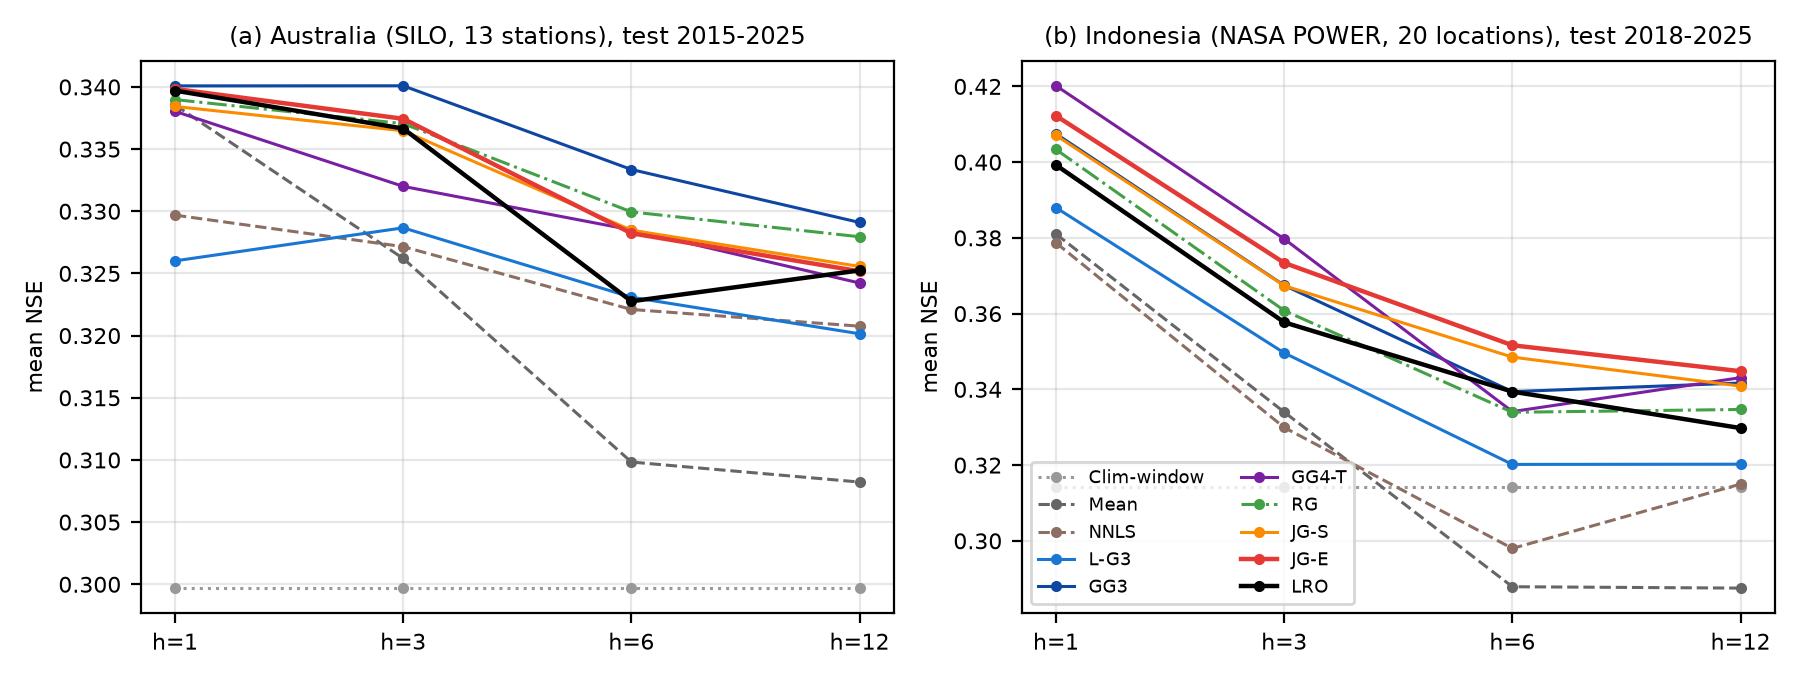

**Figure 2. MSE change of the leave-region-out gate relative to the local gate L-G3 per station and horizon (* p < 0.05 before Holm).**

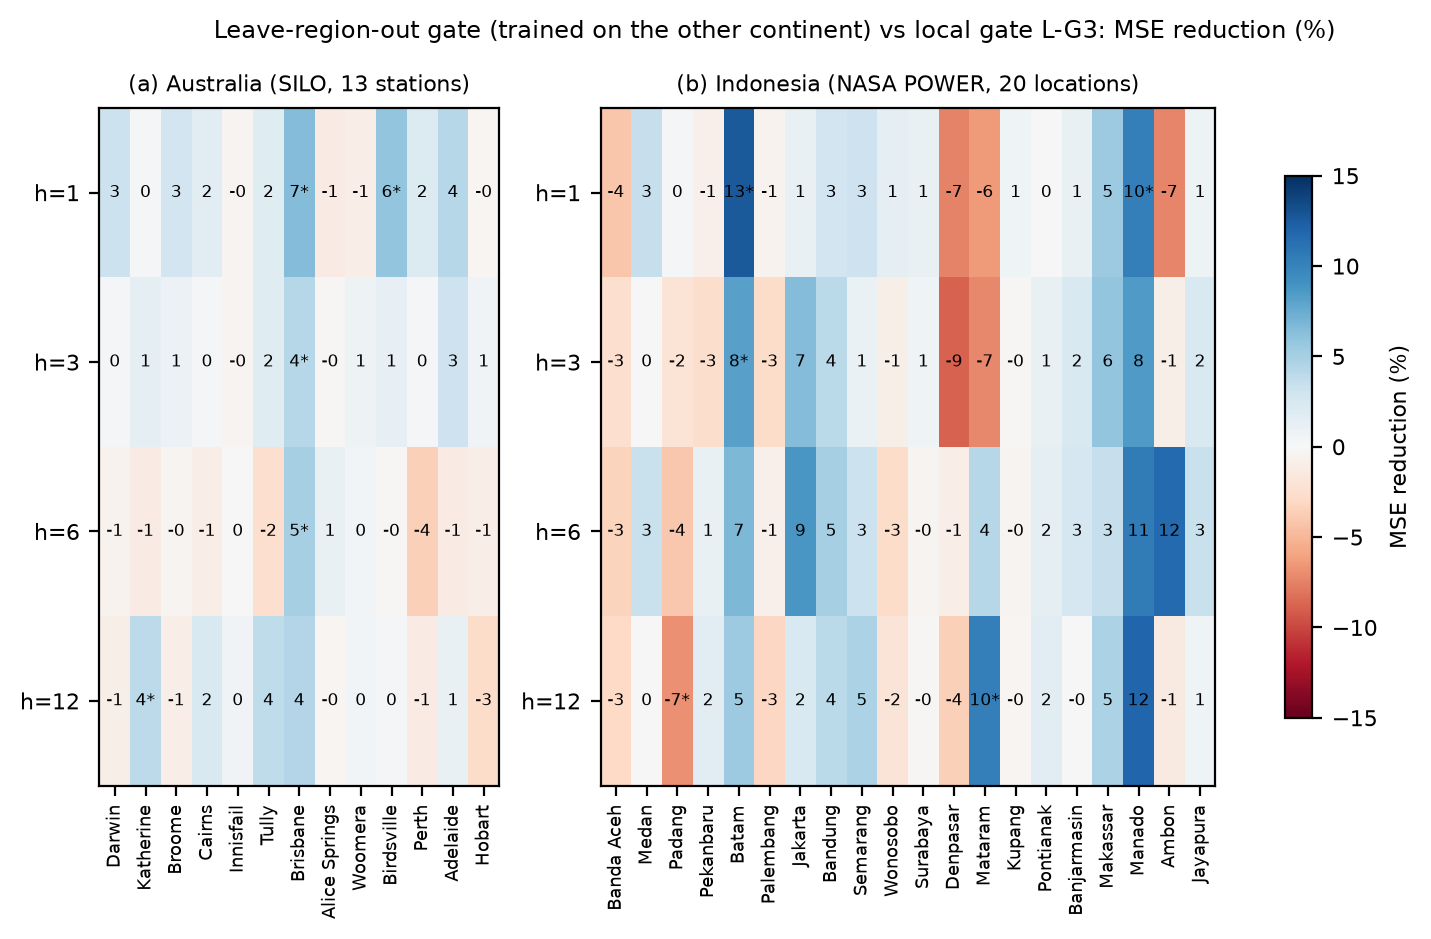

**Figure 3. Holdout NSE as a function of the number of pooled training stations.**

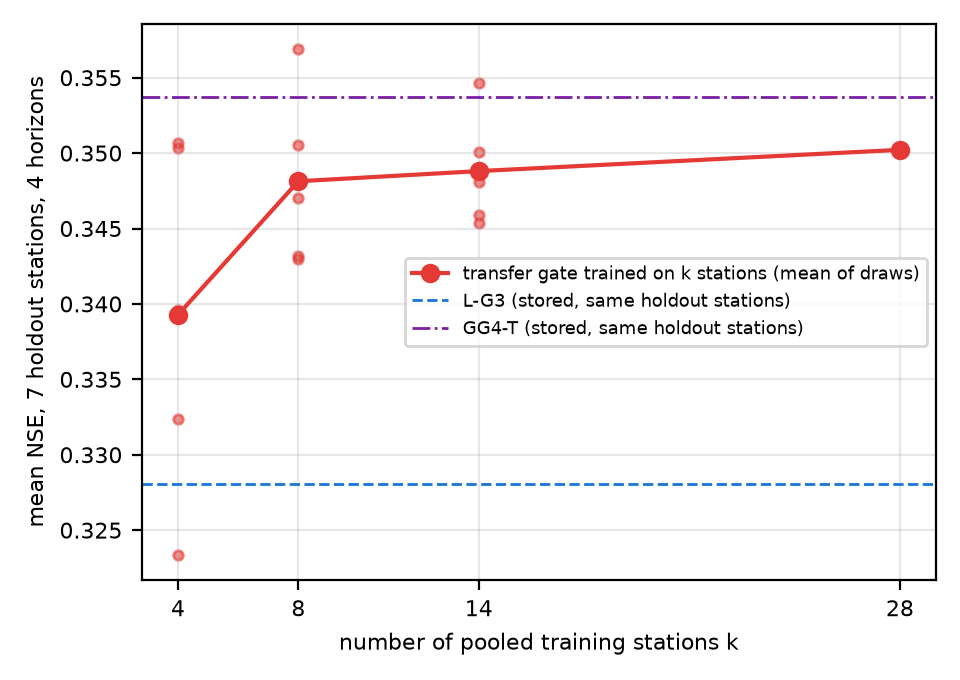

**Figure 4. JG-E weight composition per model family, by region and horizon.**

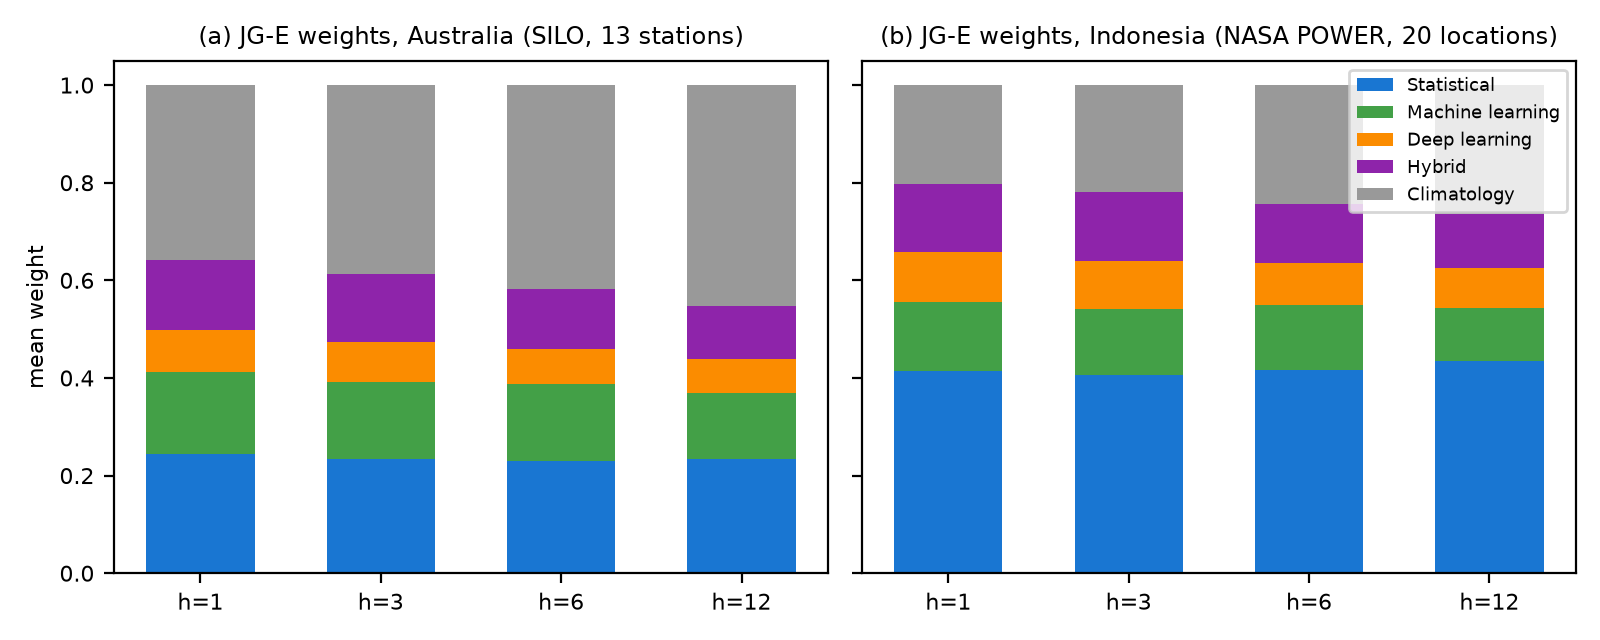

In [7]:
for f, cap in [("figure1_nse_by_horizon.png", "Figure 1. Mean NSE per horizon, Australia and Indonesia."),
               ("figure2_lro_vs_local_heatmap.png", "Figure 2. MSE change of the leave-region-out gate relative to the local gate L-G3 per station and horizon (* p < 0.05 before Holm)."),
               ("figure3_scaling_curve.png", "Figure 3. Holdout NSE as a function of the number of pooled training stations."),
               ("figure4_weights_by_family.png", "Figure 4. JG-E weight composition per model family, by region and horizon.")]:
    if (REPORTS / f).exists(): display(Markdown(f"**{cap}**")); display(Image(filename=str(REPORTS / f)))

## 5. Summary

In [8]:
display(Markdown(open(REPORTS / "summary.md", encoding="utf-8").read()))

## Australia (SILO, 13 stations), test 2015-2025

| Horizon | Clim-window | Mean | NNLS | L-G3 | GG3 | GG4-T | RG | JG-S | JG-E | LRO |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 0.300 | 0.339 | 0.330 | 0.326 | 0.340 | 0.338 | 0.339 | 0.338 | 0.340 | 0.340 |
| 3 | 0.300 | 0.326 | 0.327 | 0.329 | 0.340 | 0.332 | 0.337 | 0.336 | 0.337 | 0.337 |
| 6 | 0.300 | 0.310 | 0.322 | 0.323 | 0.333 | 0.329 | 0.330 | 0.328 | 0.328 | 0.323 |
| 12 | 0.300 | 0.308 | 0.321 | 0.320 | 0.329 | 0.324 | 0.328 | 0.326 | 0.325 | 0.325 |
| mean | 0.300 | 0.321 | 0.325 | 0.324 | 0.336 | 0.331 | 0.333 | 0.332 | 0.333 | 0.331 |

| Comparison | Wins | Median MSE change | Panel p (Holm), h = 1 / 3 / 6 / 12, squared | absolute |
|---|---|---|---|---|
| JG-E vs RG | 15/52 | -0.2% | 0.877 / 0.877 / 0.628 / 0.069 | 1.000 / 1.000 / 1.000 / 0.033 |
| JG-E vs GG3 | 14/52 | -0.4% | 0.837 / 0.629 / 0.193 / 0.193 | 1.000 / 1.000 / 0.090 / 0.001 |
| RG vs GG3 | 18/52 | -0.3% | 0.792 / 0.421 / 0.200 / 0.792 | 0.821 / 0.821 / 0.024 / 0.821 |
| JG-S vs RG | 17/52 | -0.2% | 0.809 / 0.689 / 0.210 / 0.220 | 0.882 / 0.882 / 0.882 / 0.491 |
| JG-S vs JG-E | 22/52 | -0.1% | 0.129 / 0.756 / 1.000 / 1.000 | 0.062 / 1.000 / 1.000 / 1.000 |
| JG-E vs L-G3 | 38/52 | +1.1% | 0.003 / 0.003 / 0.253 / 0.264 | 0.000 / 0.125 / 0.681 / 0.605 |
| JG-E vs NNLS | 37/52 | +1.1% | 0.146 / 0.076 / 1.000 / 1.000 | 0.002 / 0.041 / 0.409 / 0.586 |
| JG-E vs Mean | 41/52 | +1.9% | 0.311 / 0.036 / 0.036 / 0.311 | 0.011 / 0.003 / 0.000 / 0.002 |
| JG-E vs Clim-window | 43/52 | +2.5% | 0.024 / 0.024 / 0.131 / 0.170 | 0.201 / 0.622 / 1.000 / 1.000 |
| LRO vs L-G3 | 32/52 | +0.4% | 0.020 / 0.079 / 0.555 / 0.555 | 0.017 / 1.000 / 0.025 / 1.000 |
| LRO vs GG4-T | 29/52 | +0.1% | 0.976 / 0.862 / 0.862 / 0.862 | 0.029 / 0.102 / 0.138 / 0.969 |
| LRO vs GG3 | 19/52 | -0.7% | 0.982 / 0.552 / 0.010 / 0.982 | 0.692 / 0.024 / 0.000 / 0.000 |
| LRO vs NNLS | 35/52 | +0.9% | 0.173 / 0.173 / 1.000 / 1.000 | 0.010 / 0.356 / 0.702 / 0.655 |
| LRO vs Mean | 41/52 | +1.7% | 0.423 / 0.081 / 0.091 / 0.246 | 0.050 / 0.050 / 0.001 / 0.043 |
| LRO vs Clim-window | 39/52 | +2.3% | 0.041 / 0.052 / 0.266 / 0.266 | 0.303 / 0.834 / 0.834 / 0.296 |
| LRO vs L-G4 | 32/52 | +0.7% | 0.100 / 0.017 / 0.436 / 0.436 | 0.013 / 0.116 / 0.023 / 0.171 |
| JG-S vs L-G3 | 35/52 | +1.0% | 0.008 / 0.009 / 0.237 / 0.306 | 0.003 / 0.327 / 0.635 / 0.565 |
| JG-S vs NNLS | 37/52 | +1.0% | 0.254 / 0.075 / 1.000 / 1.000 | 0.006 / 0.041 / 0.334 / 0.560 |

## Indonesia (NASA POWER, 20 locations), test 2018-2025

| Horizon | Clim-window | Mean | NNLS | L-G3 | GG3 | GG4-T | RG | JG-S | JG-E | LRO |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 0.314 | 0.381 | 0.379 | 0.388 | 0.407 | 0.420 | 0.403 | 0.407 | 0.412 | 0.399 |
| 3 | 0.314 | 0.334 | 0.330 | 0.350 | 0.367 | 0.380 | 0.361 | 0.367 | 0.373 | 0.358 |
| 6 | 0.314 | 0.288 | 0.298 | 0.320 | 0.339 | 0.334 | 0.334 | 0.349 | 0.352 | 0.339 |
| 12 | 0.314 | 0.288 | 0.315 | 0.320 | 0.342 | 0.343 | 0.335 | 0.341 | 0.345 | 0.330 |
| mean | 0.314 | 0.323 | 0.330 | 0.345 | 0.364 | 0.369 | 0.358 | 0.366 | 0.371 | 0.357 |

| Comparison | Wins | Median MSE change | Panel p (Holm), h = 1 / 3 / 6 / 12, squared | absolute |
|---|---|---|---|---|
| JG-E vs RG | 52/80 | +0.6% | 0.005 / 0.004 / 0.070 / 0.461 | 0.001 / 0.001 / 0.005 / 0.005 |
| JG-E vs GG3 | 47/80 | +0.4% | 0.854 / 1.000 / 0.601 / 1.000 | 0.013 / 0.047 / 0.047 / 0.072 |
| RG vs GG3 | 32/80 | -0.3% | 0.006 / 0.002 / 0.000 / 0.025 | 0.109 / 0.030 / 0.109 / 0.072 |
| JG-S vs RG | 44/80 | +0.3% | 0.051 / 0.051 / 0.051 / 0.382 | 0.006 / 0.008 / 0.010 / 0.006 |
| JG-S vs JG-E | 35/80 | -0.3% | 0.779 / 0.807 / 1.000 / 1.000 | 0.066 / 0.066 / 0.086 / 0.000 |
| JG-E vs L-G3 | 51/80 | +2.2% | 0.000 / 0.002 / 0.007 / 0.045 | 0.002 / 0.005 / 0.002 / 0.020 |
| JG-E vs NNLS | 40/80 | -0.0% | 0.001 / 0.023 / 0.023 / 0.123 | 0.000 / 0.009 / 0.009 / 0.032 |
| JG-E vs Mean | 63/80 | +4.5% | 0.000 / 0.002 / 0.002 / 0.002 | 0.016 / 0.016 / 0.000 / 0.001 |
| JG-E vs Clim-window | 63/80 | +5.7% | 0.000 / 0.000 / 0.002 / 0.021 | 0.000 / 0.029 / 0.100 / 0.100 |
| LRO vs L-G3 | 49/80 | +1.1% | 0.000 / 0.007 / 0.057 / 0.169 | 0.004 / 0.121 / 0.121 / 0.166 |
| LRO vs GG4-T | 33/80 | -0.9% | 0.000 / 0.004 / 0.318 / 0.046 | 0.264 / 0.264 / 0.120 / 0.091 |
| LRO vs GG3 | 36/80 | -0.6% | 0.007 / 0.036 / 0.166 / 0.166 | 1.000 / 1.000 / 1.000 / 1.000 |
| LRO vs NNLS | 35/80 | -0.5% | 0.061 / 0.825 / 0.829 / 0.985 | 0.009 / 0.183 / 0.183 / 0.248 |
| LRO vs Mean | 63/80 | +3.5% | 0.000 / 0.003 / 0.003 / 0.003 | 0.093 / 0.093 / 0.002 / 0.093 |
| LRO vs Clim-window | 62/80 | +4.6% | 0.000 / 0.000 / 0.022 / 0.036 | 0.000 / 0.011 / 0.159 / 0.159 |
| LRO vs L-G4 | 51/80 | +1.2% | 0.000 / 0.002 / 0.000 / 0.395 | 0.084 / 0.002 / 0.000 / 0.343 |
| JG-S vs L-G3 | 47/80 | +1.0% | 0.000 / 0.005 / 0.012 / 0.057 | 0.020 / 0.039 / 0.011 / 0.039 |
| JG-S vs NNLS | 39/80 | -0.3% | 0.001 / 0.036 / 0.036 / 0.132 | 0.000 / 0.019 / 0.019 / 0.036 |

## Scaling curve (7 holdout stations: 3 AU + 4 ID)

| k | draws | mean NSE | sd | MSE change vs L-G3 |
|---|---|---|---|---|
| 4 | 5 | 0.339 | 0.0105 | +1.6% |
| 8 | 5 | 0.348 | 0.0052 | +2.9% |
| 14 | 5 | 0.349 | 0.0034 | +3.0% |
| 28 | 1 | 0.350 | 0.0 | +3.3% |
| ref L-G3 |  | 0.328 |  | +0.0% |
| ref NNLS |  | 0.286 |  | -9.2% |
| ref GG4-T |  | 0.354 |  | +3.5% |
| ref JG-S |  | 0.347 |  | +2.4% |
| ref JG-E |  | 0.350 |  | +3.0% |
| ref LRO |  | 0.337 |  | +1.3% |
